In [1]:
import os
import sys
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "other" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import datetime as dt

from benchmark import benchmark
from examples import example_b_mf as example_b

output_dir = Path("output") / "exp_b"

os.makedirs(output_dir, exist_ok=True)
os.makedirs(output_dir / "images", exist_ok=True)

end_date = dt.datetime(2026, 8, 1)

weights, in_sample, out_of_sample, periods, metrics, n = benchmark(
    config_module=example_b, output=output_dir, end_date=end_date, verbose=False
)


c:\Users\simon\Downloads\MonteCarlo\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\simon\Downloads\MonteCarlo\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\simon\Downloads\MonteCarlo\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_in

In [2]:
import numpy as np

reference_portfolios = {
    "World Equity 20% Conservative": np.array([0.12, 0.06, 0.02, 0.80, 0.00, 0.00, 0.00]),
    "Risk Parity": np.array([0.20, 0.00, 0.00, 0.05, 0.25, 0.25, 0.25]),
    "Balanced 40/60": np.array([0.30, 0.10, 0.00, 0.00, 0.60, 0.00, 0.00]),
    "Naive Equal Weight": np.ones(7) / 7,
    "Equal Weight Core": np.array([0.20, 0.20, 0.00, 0.00, 0.20, 0.20, 0.20]),
}

reference_colors = {
    "World Equity 20% Conservative": "orange",
    "Risk Parity": "yellow",
    "Balanced 40/60": "green",
    "Naive Equal Weight": "red",
    "Equal Weight Core": "purple",
}


In [3]:
from src.metrics.cvar import CVaR

CVAR_ALPHA = 0.05
cvar_metric = CVaR(alpha=CVAR_ALPHA)

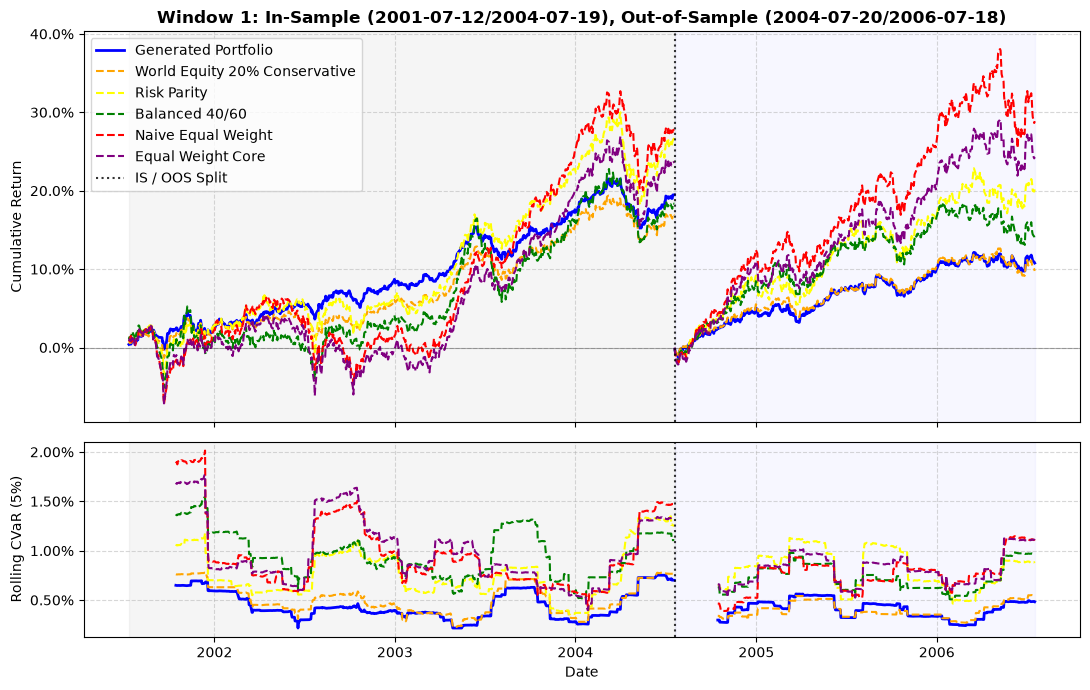

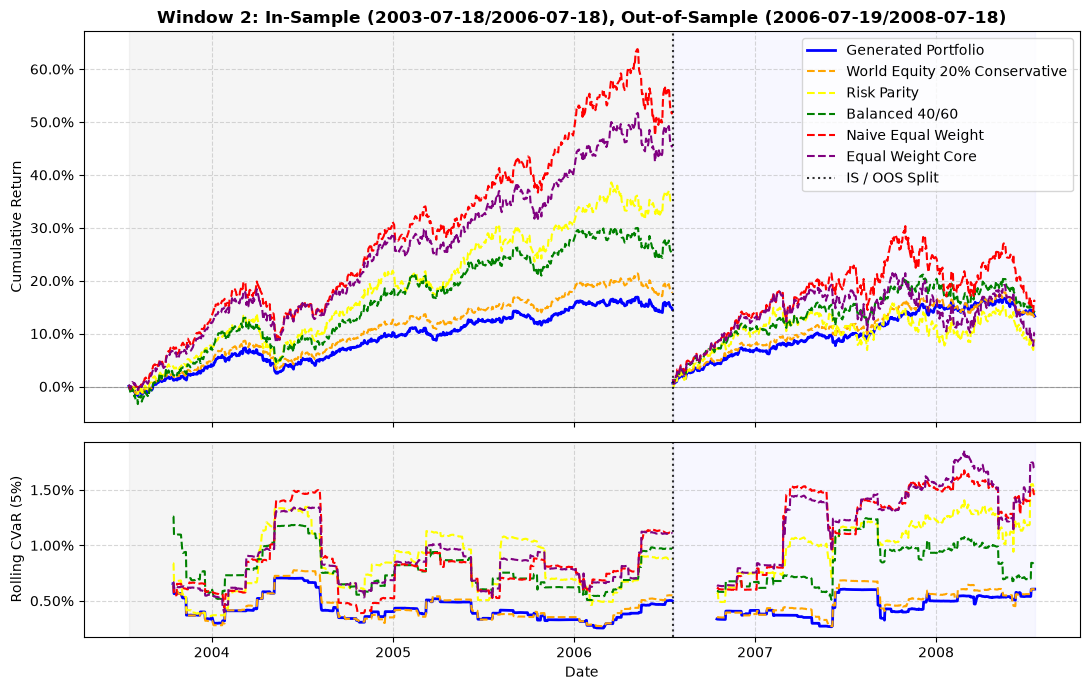

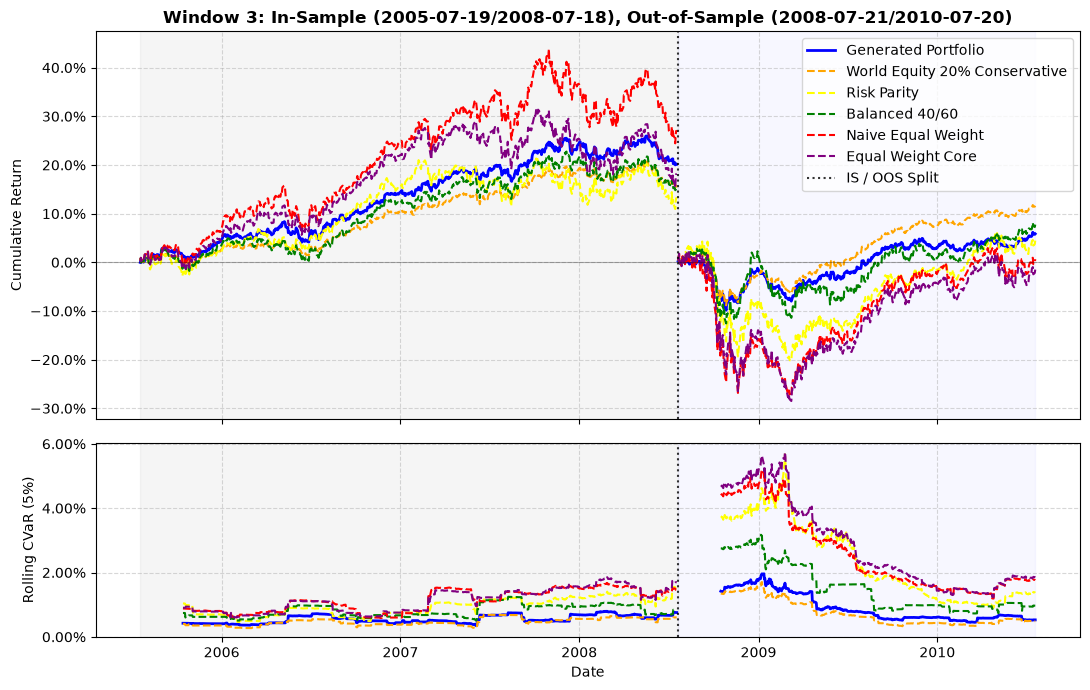

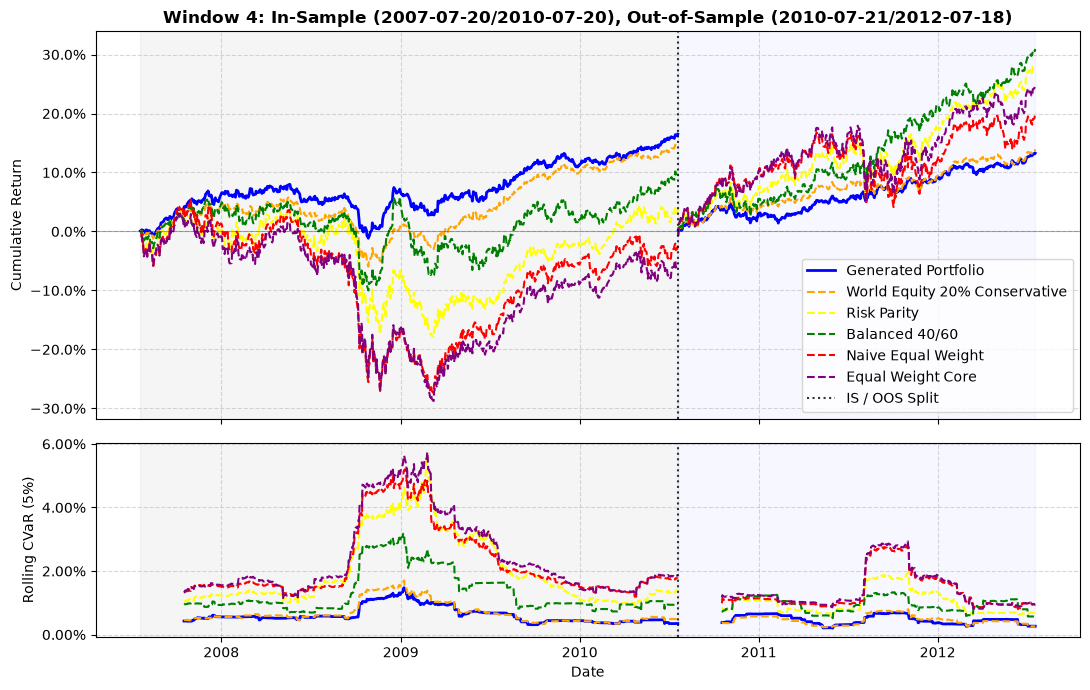

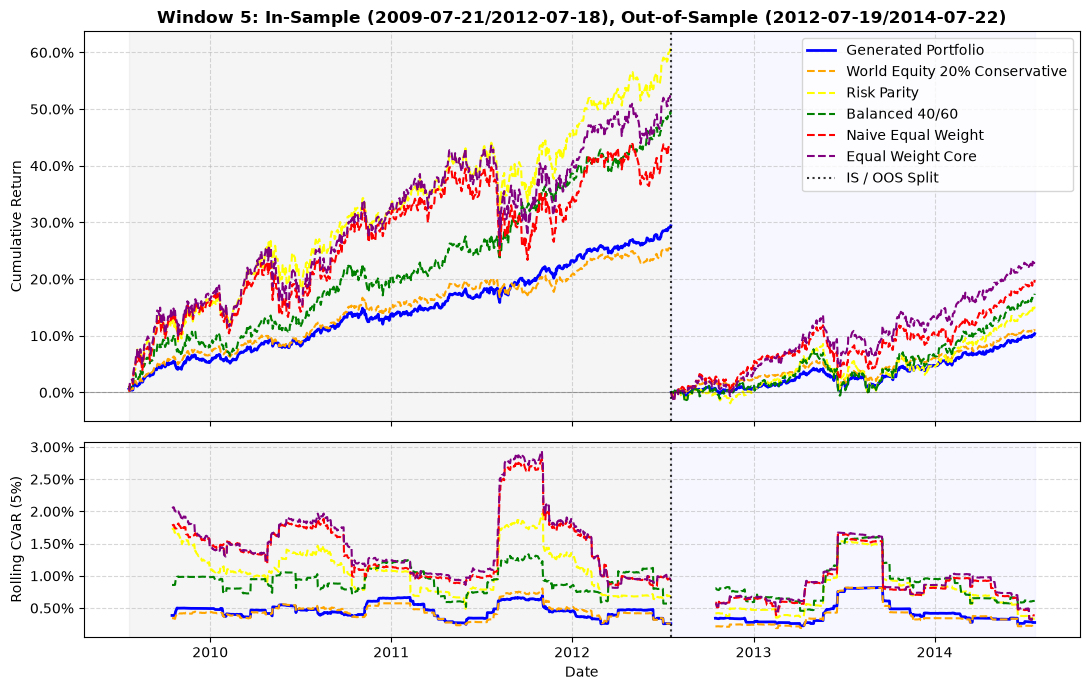

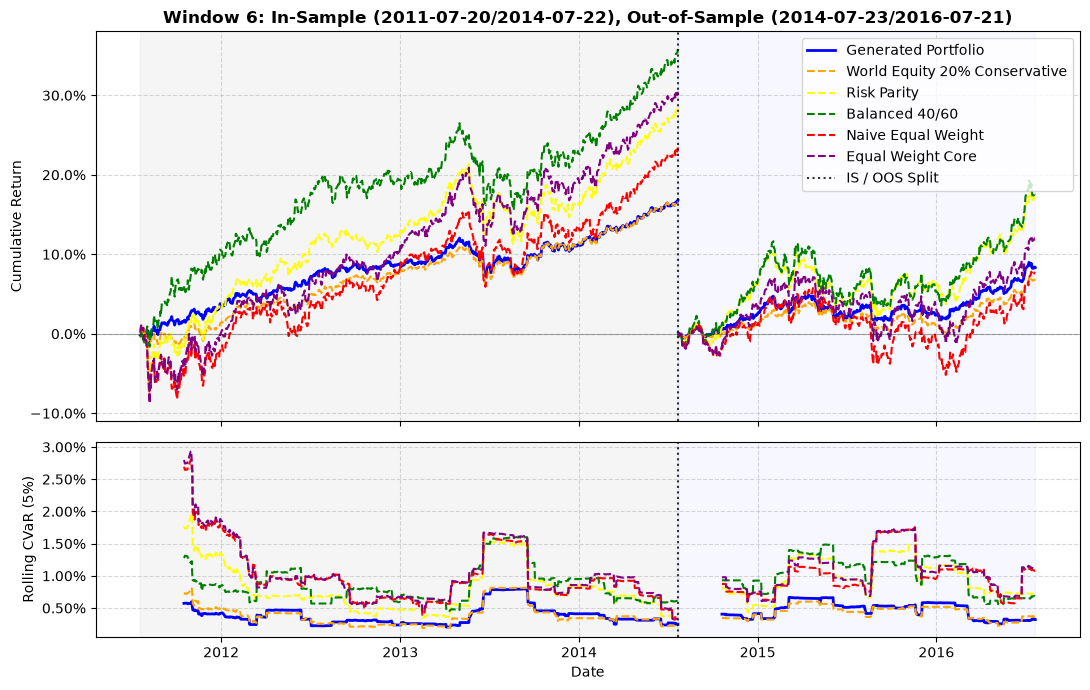

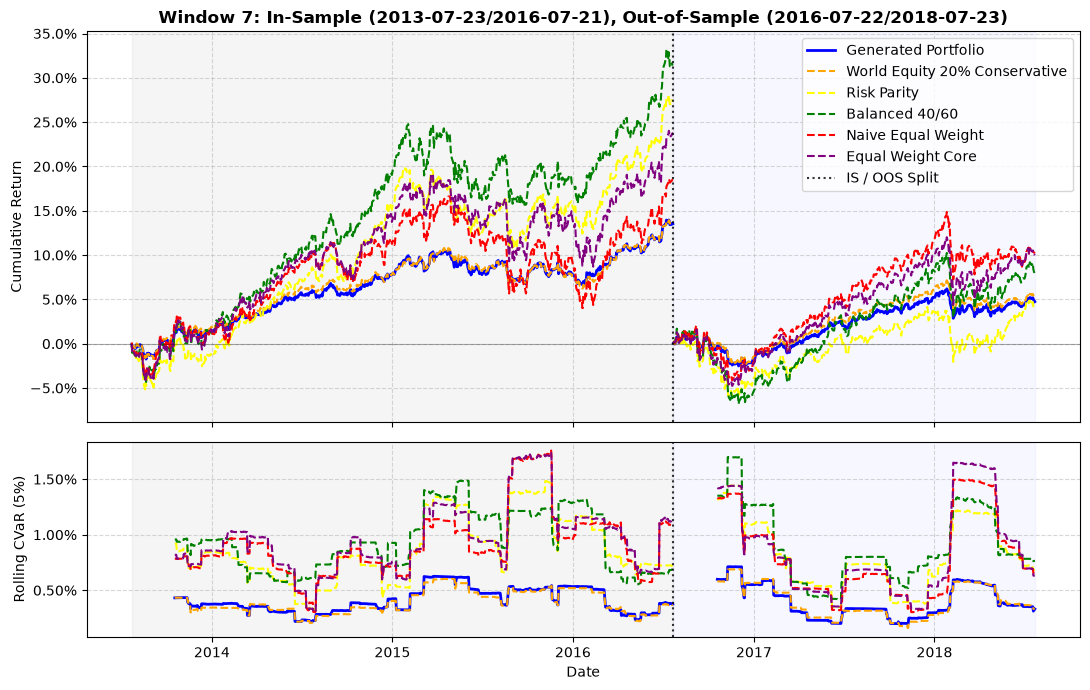

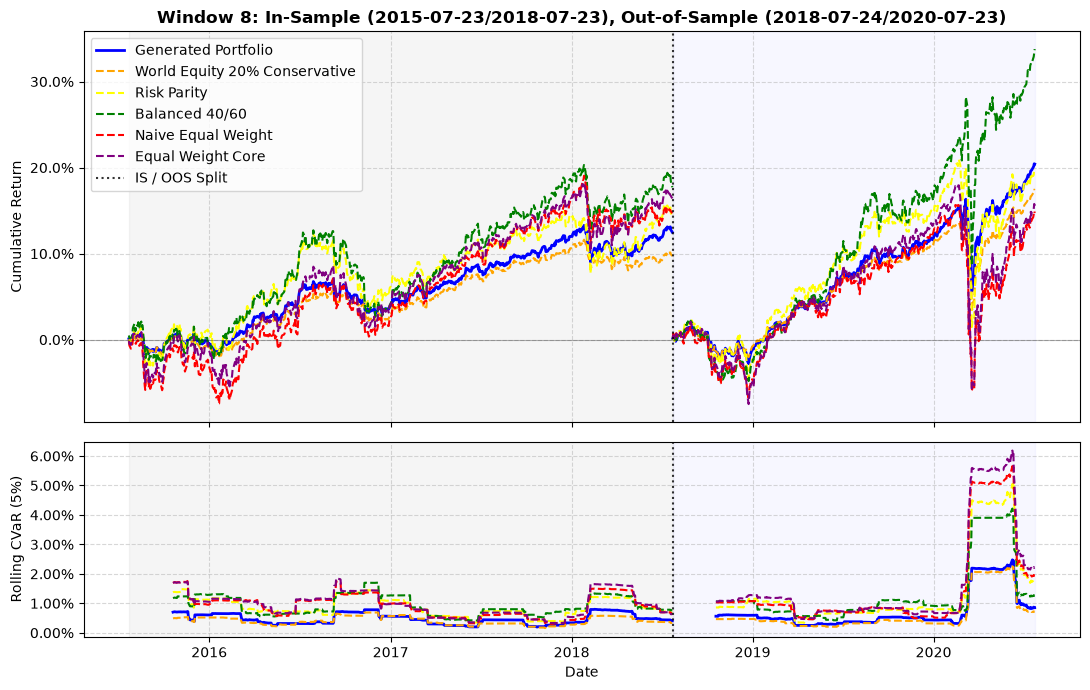

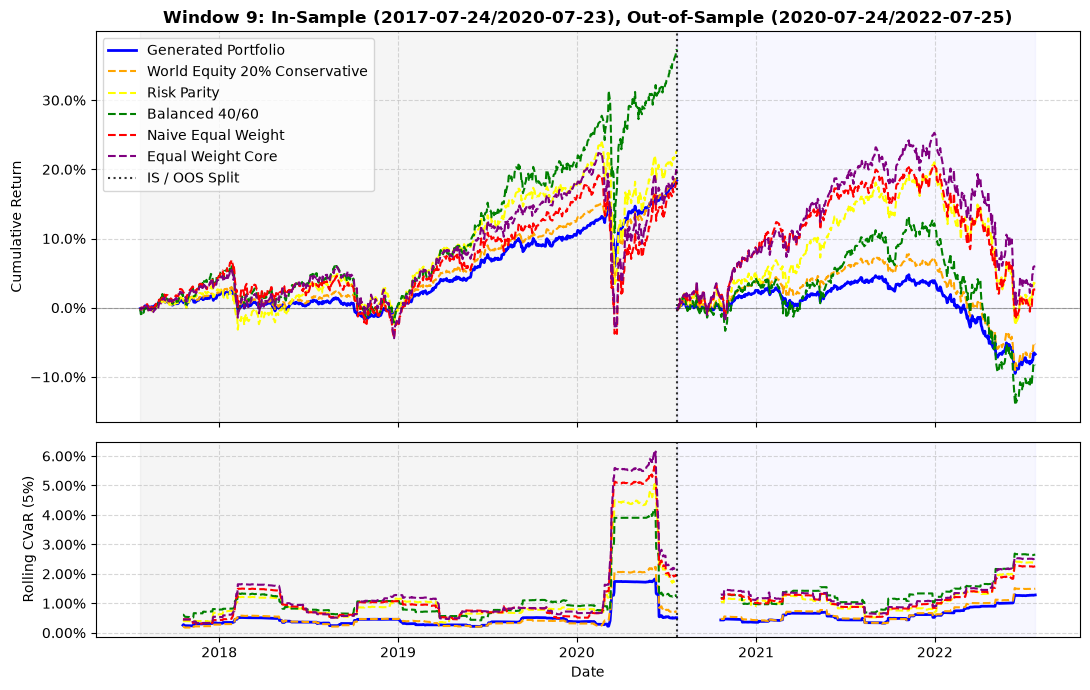

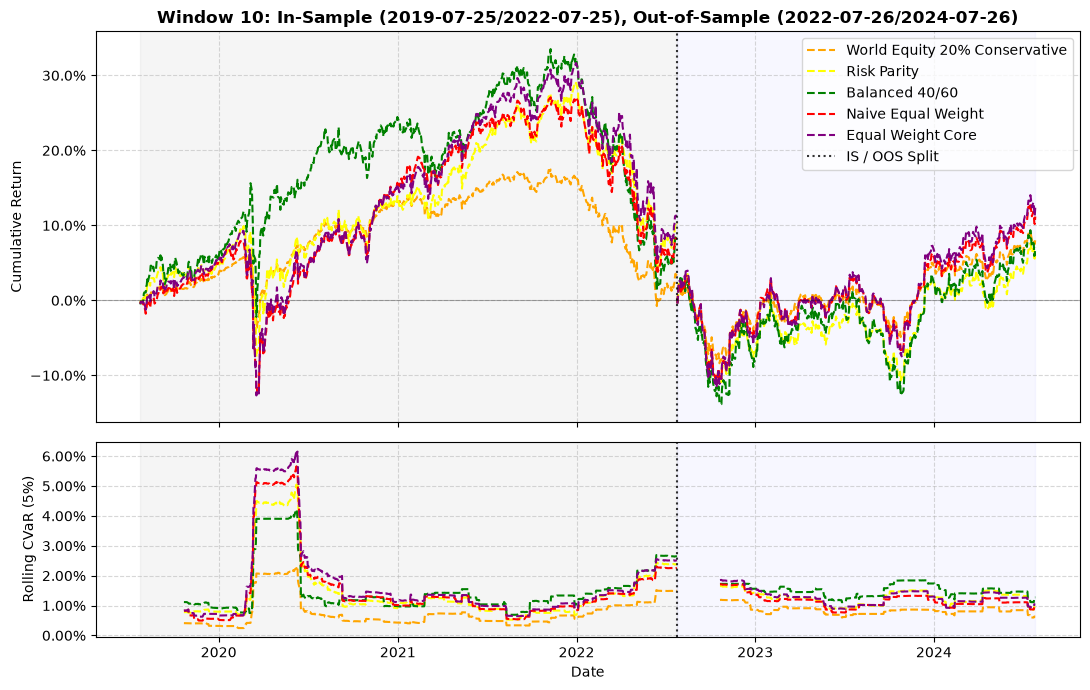

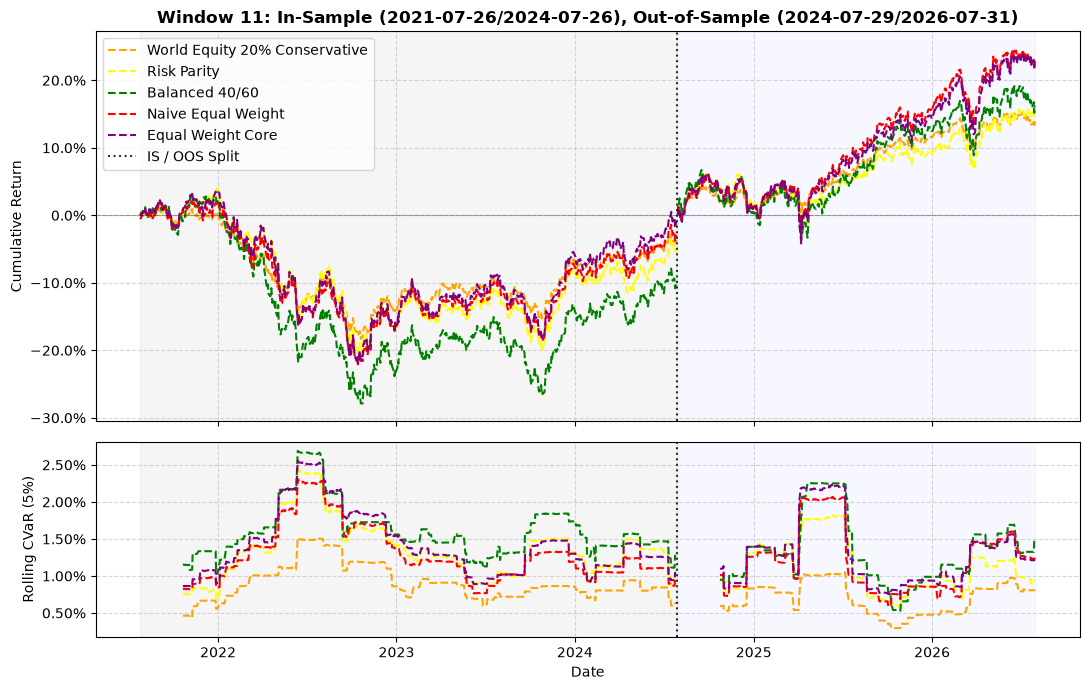

In [4]:
from other.utils import compute_rolling_cvar, display_and_save

display_and_save(
    n_windows=n,
    periods=periods,
    weights=weights,
    out_of_sample=out_of_sample,
    reference_portfolios=reference_portfolios,
    reference_colors=reference_colors,
    output_dir=output_dir,
    compute_metric=compute_rolling_cvar,
    metric=cvar_metric,
    alpha=CVAR_ALPHA,
    in_sample=in_sample
)

In [5]:
from other.utils import save_metrics

save_metrics(
    metrics=metrics,
    n_windows=n,
    config=example_b,
    reference_portfolios=reference_portfolios,
    in_sample=in_sample,
    out_of_sample=out_of_sample,
    output_dir=output_dir,
)

Metrics for Window 1:
    Window                      Portfolio    Metric  InSample  OutOfSample  \
0        1            Generated Portfolio      CVaR  0.005103     0.004555   
1        1            Generated Portfolio  Drawdown  0.051734     0.024978   
2        1            Generated Portfolio       ENC  3.800232     3.800232   
3        1            Generated Portfolio       ENB  4.742238     3.855114   
4        1            Generated Portfolio      CAGR  0.061103     0.052493   
5        1  World Equity 20% Conservative      CVaR  0.005496     0.004555   
6        1  World Equity 20% Conservative  Drawdown  0.049139     0.031214   
7        1  World Equity 20% Conservative       ENC  1.518834     1.518834   
8        1  World Equity 20% Conservative       ENB  5.375614     4.315648   
9        1  World Equity 20% Conservative      CAGR  0.053397     0.047724   
10       1                    Risk Parity      CVaR  0.008853     0.008889   
11       1                    Risk Parity 